# Notebook 00 — Setup, sanity checks and your first drive

**The project in one sentence:** we teach a small simulated robot car to follow spoken-style instructions such as
*"drive to the red ball"*, using its camera only, with a **vision-language-action model (VLA)**: smolVLA, a
450-million-parameter model from Hugging Face. First it learns by copying demonstrations (imitation learning), then
it practises on its own (reinforcement learning).

**Goal of this notebook:** make sure the machine, the simulator and the robot car all work *before* we build
anything on top of them. By the end you will have:

1. Checked which hardware PyTorch can use (NVIDIA GPU, Apple Silicon GPU or CPU) and measured how fast it is.
2. Learned the basic Genesis workflow (init → scene → build → step).
3. Understood how our mecanum car is modelled, and *why* it is modelled that way.
4. Verified with plots that the car actually does what we tell it to.
5. Driven the car yourself with the keyboard.

### Where this fits in the project

| # | Notebook | What happens | Time (RTX 4080-class GPU) |
|---|---|---|---|
| 00 | Setup & first drive | hardware check, how the car works, drive it with the keyboard | 15 min |
| 01 | Environment design | random rooms, goal objects, prompts, success, a scripted expert driver | 15 min |
| 02 | Recording demonstrations | the LeRobot data format, a few drives of your own (hands-on), 300 scripted drives (the training data) | 30 min |
| 03 | Preparing the data | train/validation split, action chunks, scaling, augmentation, the data loader | 10 min |
| 04 | Imitation training | smolVLA's reader + two action heads (smolVLA's and a car-specific one), tests and charts | 2.5 h |
| 05 | Reinforcement learning | PPO: the car practises in 8 parallel simulators | 1 h + as long as you like |

Run the notebooks **in order**: each one saves files (in `runs/`) that the next one uses.

**A habit worth building:** every time we add a component, we test it in isolation and *look at a
plot* before using it. Bugs in robotics are often silent: the code runs, but the robot does
something subtly wrong (a flipped sign, a wrong unit). A plot catches these in seconds, while a
trained model hides them for days.

> The simulation code lives in the `carsim/` package next to this folder. The notebooks import it
> so they can focus on *ideas* rather than hundreds of lines of plumbing. Open the files whenever
> you want to see the details; each one starts with a comment explaining its design.

## 1. Setup: make the project code importable

Jupyter starts Python inside the `notebooks/` folder, so Python does not automatically know about
the `carsim/` package one folder up. We add the project root to Python's search path.
We also keep any files this notebook produces in a `runs/` folder.

In [1]:
import sys, time
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
RUNS = PROJECT_ROOT / "runs"
RUNS.mkdir(exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("Project root:", PROJECT_ROOT)

Project root: /home/mayur/Projects/obstacle_avoidance


## 2. Hardware check: which device will do the maths?

**Why it matters.** Neural networks are mostly giant matrix multiplications. A GPU has thousands of
small cores that do these in parallel, typically 10–100× faster than a CPU. PyTorch can use three kinds of hardware:

| Device name | What it is | Notes for this project |
|---|---|---|
| `cuda` | an NVIDIA GPU (CUDA is NVIDIA's software layer for it) | what the project was built on (RTX 4080 SUPER, 16 GB); all timings in the notebooks are from it |
| `mps` | the GPU of an Apple Silicon Mac (M1–M4; "Metal Performance Shaders") | works, but expect training to be several times slower; the model runs in full precision there (see 2.1) |
| `cpu` | no GPU | fine for notebooks 00–03; training in notebooks 04–05 would take days |

`carsim/device.py` picks the best one automatically (`cuda` > `mps` > `cpu`); every notebook and script uses it, so
nothing else needs changing. You can force a choice with the environment variable `CARSIM_DEVICE=cpu`.

**Memory is the budget.** On a GPU, the *VRAM* (16 GB here) limits how big a model we can train. On a Mac the GPU
shares the normal memory. This is the reason for several design decisions later, for example training only part
of smolVLA.

In [2]:
import torch
from carsim.device import pick_device, describe
DEVICE = pick_device()
print(describe())
if DEVICE == "cuda":
    print("bf16 support:", torch.cuda.is_bf16_supported())

device = cuda: NVIDIA GeForce RTX 4080 SUPER, 15.6 GB | PyTorch 2.15.0+cu134 | Linux 7.2.14-arch1-1
bf16 support: True


### 2.1 How fast is this device? (and why "bf16" matters)

We time a large matrix multiplication in two number formats:

* **fp32** — standard 32-bit floating point numbers.
* **bf16** — "brain float 16", 16-bit numbers with the same *range* as fp32 but less *precision*.
  NVIDIA GPUs have special hardware (*tensor cores*) for 16-bit maths, and the numbers take half the
  memory. Neural networks tolerate the lost precision well, which is why large models are usually
  trained in bf16.

We report **TFLOPS** (trillions of floating-point operations per second). Multiplying two n×n
matrices takes about 2·n³ operations. On an NVIDIA GPU expect bf16 to be several times faster than fp32: that gap
is why the project runs smolVLA in bf16 there. On a Mac (`mps`) bf16 support in PyTorch is incomplete, so the
project uses fp32 there; the cell skips bf16 if it isn't supported. On a CPU the test uses a smaller matrix.

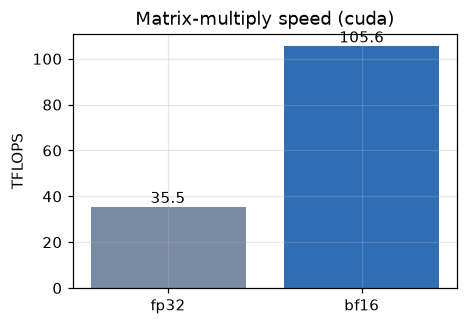

In [3]:
from carsim.device import synchronize

def matmul_tflops(dtype, n=8192, reps=20):
    a = torch.randn(n, n, device=DEVICE, dtype=dtype)
    b = torch.randn(n, n, device=DEVICE, dtype=dtype)
    for _ in range(3):           # warm-up: the first calls include one-time setup costs
        a @ b
    synchronize(DEVICE)          # GPU calls are asynchronous; wait for them before timing
    t = time.perf_counter()
    for _ in range(reps):
        a @ b
    synchronize(DEVICE)
    return 2 * n**3 * reps / (time.perf_counter() - t) / 1e12

n = 8192 if DEVICE != "cpu" else 2048
results = {"fp32": matmul_tflops(torch.float32, n)}
try:
    results["bf16"] = matmul_tflops(torch.bfloat16, n)
except (RuntimeError, TypeError) as e:
    print("bf16 not supported on this device:", str(e)[:100])
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(results.keys(), results.values(), color=["#7a8ca3", "#2f6db5"][: len(results)])
for i, v in enumerate(results.values()):
    ax.text(i, v, f"{v:.1f}", ha="center", va="bottom")
ax.set_ylabel("TFLOPS"); ax.set_title(f"Matrix-multiply speed ({DEVICE})")
plt.show()

## 3. Genesis in four steps

[Genesis](https://genesis-world.readthedocs.io) is the physics simulator. Every Genesis program
follows the same pattern:

1. **`gs.init()`** — start the engine once per Python process and choose CPU or GPU. On a Mac, "GPU" means
   Apple's Metal; without any GPU, Genesis runs on the CPU (`carsim.device.sim_backend()` picks for you).
2. **Create a `Scene`** and add *entities* to it (floor, walls, objects, robots) and *cameras*.
3. **`scene.build()`** — Genesis compiles the whole scene into fast GPU code. **This is slow the
   first time (~1 minute)** because GPU kernels are being compiled. Compiled kernels are cached on
   disk, so later builds are much faster.
4. **`scene.step()`** — advance physics by one small time step (`dt`). We use **dt = 0.01 s
   (100 Hz)**. Small steps keep contacts stable. The car's "brain" (you, or later the neural
   network) makes decisions less often, at **10 Hz**. So every decision is held for 10 physics steps.

> ⚠️ `gs.init()` may only run once per Python process. If you want to start over, use
> *Kernel → Restart Kernel* rather than re-running this cell.

In [4]:
import genesis as gs
from carsim.device import sim_backend
if not gs._initialized:
    gs.init(backend=sim_backend(), logging_level="warning")
print("Genesis", gs.__version__, "ready")

[I 11/13/26 14:22:13.238 762585] [shell.py:_shell_pop_print@25] Graphical python shell detected, using wrapped sys.stdout


Genesis 1.4.6 ready


## 4. The car: how a mecanum wheel works, and how we model it

### 4.1 Real mecanum wheels

A mecanum wheel has small free-spinning **rollers around its rim, set at 45°**. Because the rollers
spin freely, the wheel can only push the ground *along one diagonal*. With four wheels arranged in an
"X" pattern, combining the four diagonal pushes lets the car:

* drive forward/back like a normal car (`vx`),
* **slide sideways without turning** (`vy`, called *strafing*),
* rotate on the spot (`wz`),
* or any mix of the three at the same time.

A robot that can move in any direction in the plane without first turning is called
**holonomic**. Our car's whole action space is these three numbers: **(vx, vy, wz)** — forward
speed (m/s), leftward speed (m/s) and counter-clockwise turn rate (rad/s), all measured in the
car's *own* frame of reference (so "forward" always means "where the camera points").

### 4.2 Why we do *not* simulate the rollers

Simulating mecanum physics faithfully would need ~40 tiny rollers, each in contact with the
ground. In Genesis, friction is the same in every direction (there is no "slippery along one axis"
option), so the roller trick cannot be shortcut. Tiny contacts are also slow and jittery in any
physics engine.

**Our decision: a *kinematic holonomic base*.** The chassis hangs from three motorised joints
(*slide along x → slide along y → rotate about z*). Every physics step we convert the command
(vx, vy, wz) from the car's frame into world-frame joint velocities, and a velocity controller drives
the joints. The motors have a **force limit**, so walls and obstacles still stop the car.

| We keep | We give up |
|---|---|
| Exact, repeatable motion (great for learning) | Wheel slip and skidding |
| Collisions stop the car | Tipping over and bumpy terrain |
| Fast simulation (important for RL) | Motor and battery dynamics |

For a flat indoor arena these losses are small. If the model ever runs on a real robot, the gap
between perfect simulated motion and messy real motion (the *sim-to-real gap*) would need extra
work, for example adding random noise to the motion during training.

### 4.3 From body velocity to wheel speeds (inverse kinematics)

The wheels in our simulation are visual only, but they still spin at exactly the speeds a real
robot would need. This is the formula a real robot's microcontroller would run:

$$
\begin{aligned}
\omega_{FL} &= (v_x - v_y - k\,\omega_z)/r \qquad & \omega_{FR} &= (v_x + v_y + k\,\omega_z)/r \\
\omega_{RL} &= (v_x + v_y - k\,\omega_z)/r & \omega_{RR} &= (v_x - v_y + k\,\omega_z)/r
\end{aligned}
$$

where $r$ is the wheel radius and $k = l_x + l_y$ (the half wheelbase plus the half track width).
The plot below shows the **wheel-spin pattern** for each basic motion. Notice that:

* **forward**: all four wheels spin the same way;
* **strafe left**: the diagonals spin in *opposite* directions;
* **rotate**: the left side spins backwards and the right side forwards, like a tank.

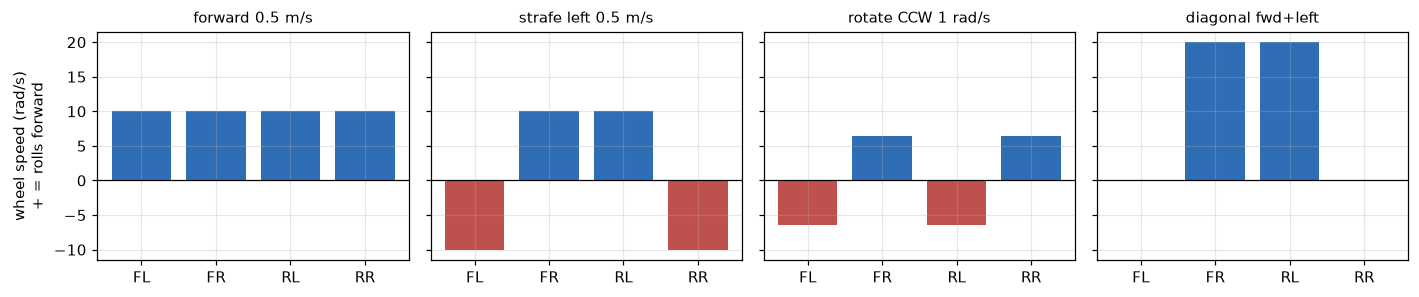

In [5]:
from carsim.config import CarConfig, SimConfig
from carsim.mecanum import wheel_speeds, WHEEL_NAMES

car_cfg, sim_cfg = CarConfig(), SimConfig()
motions = {"forward 0.5 m/s": (0.5, 0, 0), "strafe left 0.5 m/s": (0, 0.5, 0),
           "rotate CCW 1 rad/s": (0, 0, 1.0), "diagonal fwd+left": (0.5, 0.5, 0)}
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8), sharey=True)
for ax, (name, cmd) in zip(axes, motions.items()):
    w = wheel_speeds(*cmd, car_cfg)
    ax.bar([n.upper() for n in WHEEL_NAMES], w, color=["#2f6db5" if v >= 0 else "#c0504d" for v in w])
    ax.axhline(0, color="k", lw=0.8); ax.set_title(name, fontsize=10)
axes[0].set_ylabel("wheel speed (rad/s)\n+ = rolls forward")
plt.tight_layout(); plt.show()

### 4.4 The car's parameters

All tunable numbers live in two small config classes, so you can see and change them in one place.
The important ones for now:

* **Size**: about 40 × 26 cm, roughly a hobby-robot chassis.
* **Speed limits**: 0.8 m/s forward, 0.6 m/s sideways, 1.5 rad/s rotation. Fast enough to cross an
  8 m arena in about 10 s, and slow enough to steer precisely at 10 Hz.
* **FPV camera**: 16 cm above the ground, tilted 10° down, 75° field of view, **256×256 pixels**.
  This image is the *only* thing the AI model will see, so it needs to show both the floor right in
  front of the car (obstacles) and things far away (goal objects).

In [6]:
from dataclasses import asdict
print("CarConfig:"); [print(f"  {k:15s} = {v}") for k, v in asdict(car_cfg).items()]
print("SimConfig:"); [print(f"  {k:15s} = {v}") for k, v in asdict(sim_cfg).items()]
print(f"  -> {sim_cfg.substeps} physics steps per control step")

CarConfig:
  chassis_length  = 0.4
  chassis_width   = 0.26
  chassis_height  = 0.06
  chassis_mass    = 3.0
  wheel_radius    = 0.05
  wheel_width     = 0.04
  wheel_mass      = 0.15
  wheelbase_half  = 0.15
  track_half      = 0.17
  n_rollers       = 10
  cam_forward     = 0.17
  cam_height      = 0.16
  cam_pitch_deg   = 10.0
  cam_fov_deg     = 75.0
  cam_res         = (256, 256)
  max_vx          = 0.8
  max_vy          = 0.6
  max_wz          = 1.5
  kv_linear       = 400.0
  kv_yaw          = 40.0
  max_force       = 60.0
  max_torque      = 15.0
SimConfig:
  sim_dt          = 0.01
  control_hz      = 10.0
  accel_linear    = 1.5
  decel_linear    = 3.0
  accel_yaw       = 4.0
  decel_yaw       = 8.0
  -> 10 physics steps per control step


## 5. Build a scene with the car

We create a **walled 8 × 8 m arena** with three coloured landmarks (a red sphere, a green box and a
blue cylinder), add the car, and add one extra "outside" camera so we can see the car from a third-person view.

About the **FPV camera**: it is *attached* to the chassis, so every time the car moves we call
`move_to_attach()` and the camera follows. (Graphics cameras look along their own −z axis; the
small matrix in `car.py` rotates that axis to point out of the car's front bumper.)

`show_viewer=False` means no window opens. We render images ourselves and display them inline.
This "headless" mode is also how RL training will run.

⏳ *The build takes about a minute the first time.*

In [7]:
from carsim.arena import add_walled_arena, add_demo_objects
from carsim.car import MecanumCar

scene = gs.Scene(sim_options=gs.options.SimOptions(dt=sim_cfg.sim_dt),
                 show_viewer=False, renderer=gs.renderers.Rasterizer())
add_walled_arena(scene)
add_demo_objects(scene)
car = MecanumCar(scene, car_cfg, sim_cfg)
outside_cam = scene.add_camera(res=(640, 480), pos=(-3.6, -1.3, 1.0), lookat=(-2.5, 0, 0.1), fov=45)

t = time.perf_counter()
scene.build()
car.on_built()
print(f"scene.build() took {time.perf_counter() - t:.1f} s")
START = (-2.5, 0.0, 0.0)   # x, y (metres), yaw (radians): west side of the arena, facing east (+x)
car.reset(*START)

scene.build() took 1.6 s


### 5.1 What does the car see?

Left: the third-person view. Right: **the FPV image, exactly what the model will receive**. The red
sphere is straight ahead (5 m away), so it should appear in the centre of the FPV image.

Things to check: the horizon sits a little above the image centre (the camera is tilted down), and
the floor directly in front of the bumper is visible, so the car can "see" obstacles before it hits them.

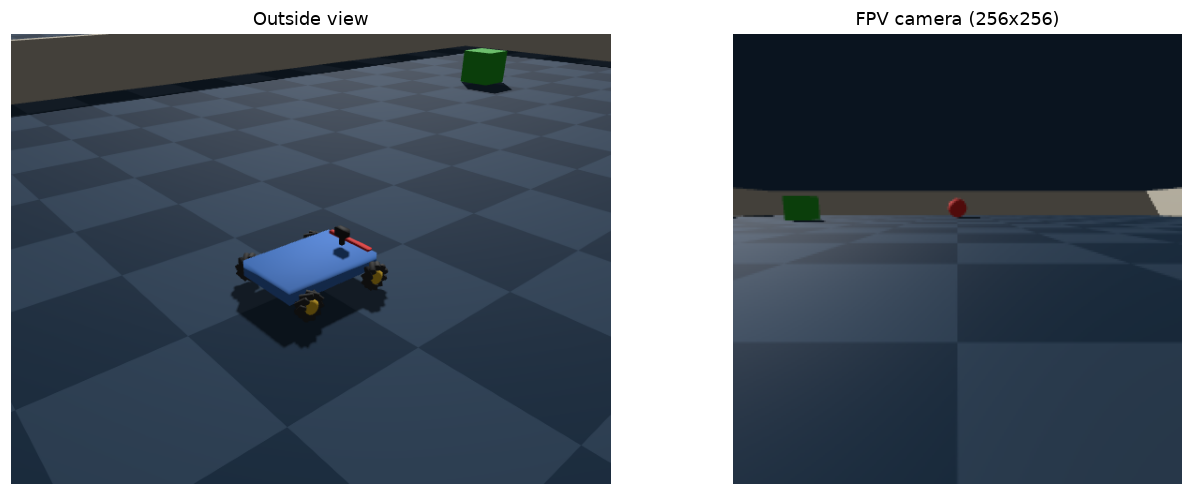

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.33, 1]})
axes[0].imshow(outside_cam.render()[0]); axes[0].set_title("Outside view")
axes[1].imshow(car.render_fpv()); axes[1].set_title(f"FPV camera ({car_cfg.cam_res[0]}x{car_cfg.cam_res[1]})")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Test drive with a script: does the car do what we command?

Before trusting the car with keyboard driving or a neural network, we feed it a **known sequence of
commands** and measure what it actually does. This is called checking **command tracking**.

The script runs: forward → strafe left → rotate 90° → diagonal → stop.

**How to read the plots:**
* **Top three panels**: dashed = commanded, solid = measured velocity. They should overlap almost
  perfectly, apart from a tiny lag at each change. A large gap, an overshoot or oscillation would
  mean the controller gains (`kv_linear`, `kv_yaw`) are badly tuned.
* **Bottom-left**: the path seen from above. Arrows show which way the car is *facing*. During the
  strafe, the car should move sideways while the arrows keep pointing the same way. That is the
  mecanum ability in action.

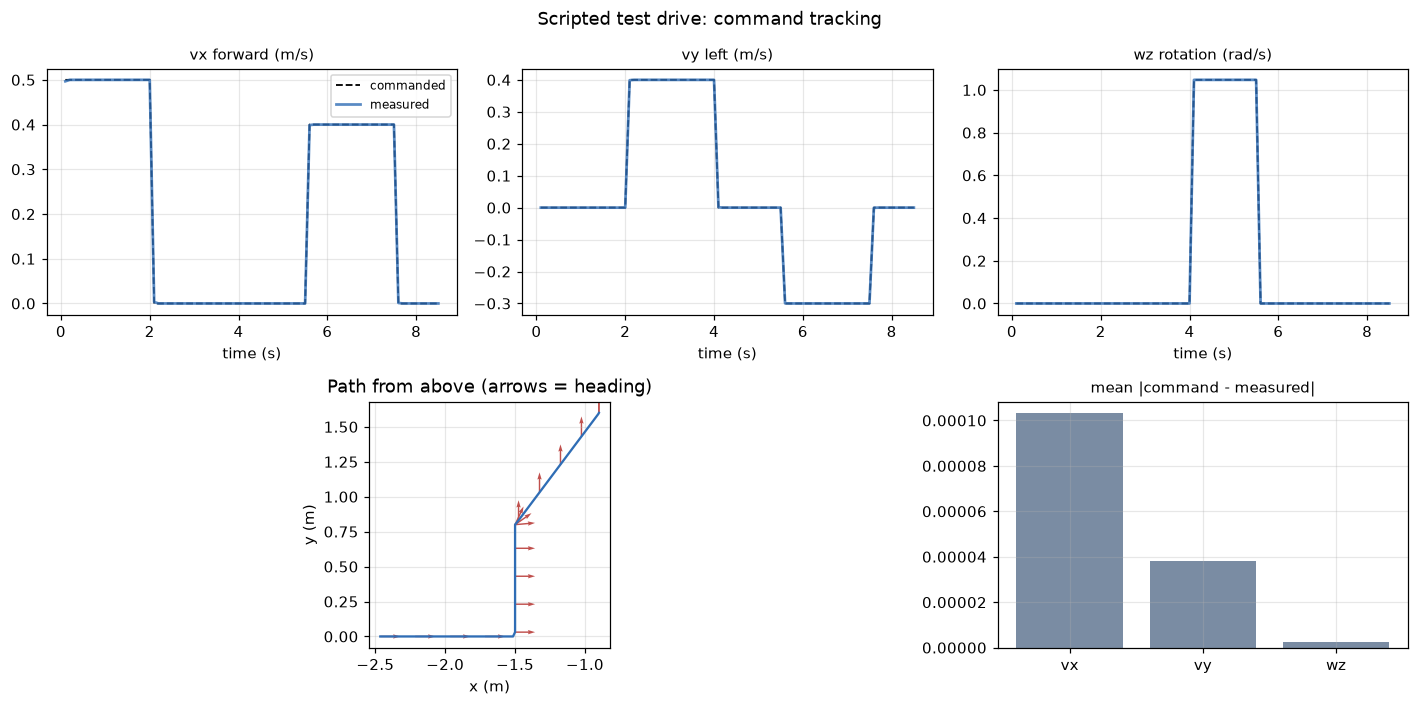

Final pose (x, y, yaw in deg): [-0.9  1.6] 90.0


In [9]:
def run_commands(plan, start=START):
    # plan = list of ((vx, vy, wz), seconds). Returns arrays of time, command, measured velocity, pose.
    car.reset(*start)
    log = {"t": [], "cmd": [], "vel": [], "pose": []}
    t = 0.0
    for cmd, seconds in plan:
        for _ in range(int(round(seconds * sim_cfg.control_hz))):
            car.step(*cmd)
            t += 1 / sim_cfg.control_hz
            log["t"].append(t); log["cmd"].append(cmd)
            log["vel"].append(car.body_velocity()); log["pose"].append(car.pose())
    return {k: np.asarray(v) for k, v in log.items()}

plan = [((0.5, 0, 0), 2.0), ((0, 0.4, 0), 2.0), ((0, 0, np.pi / 2 / 1.5), 1.5),
        ((0.4, -0.3, 0), 2.0), ((0, 0, 0), 1.0)]
log = run_commands(plan)

def plot_tracking(log, title):
    fig = plt.figure(figsize=(13, 6.5)); gsp = fig.add_gridspec(2, 3)
    labels = ["vx forward (m/s)", "vy left (m/s)", "wz rotation (rad/s)"]
    for i in range(3):
        ax = fig.add_subplot(gsp[0, i])
        ax.plot(log["t"], log["cmd"][:, i], "k--", lw=1.2, label="commanded")
        ax.plot(log["t"], log["vel"][:, i], color="#2f6db5", lw=1.8, alpha=0.8, label="measured")
        ax.set_title(labels[i], fontsize=10); ax.set_xlabel("time (s)")
    fig.axes[0].legend(fontsize=8)
    ax = fig.add_subplot(gsp[1, 0:2])
    p = log["pose"]; ax.plot(p[:, 0], p[:, 1], color="#2f6db5")
    k = slice(None, None, 5)
    ax.quiver(p[k, 0], p[k, 1], np.cos(p[k, 2]), np.sin(p[k, 2]), color="#c0504d", width=0.006, scale=12)
    ax.set_aspect("equal"); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_title("Path from above (arrows = heading)")
    ax = fig.add_subplot(gsp[1, 2])
    err = np.abs(log["cmd"] - log["vel"])
    ax.bar(["vx", "vy", "wz"], err.mean(0), color="#7a8ca3"); ax.set_title("mean |command - measured|", fontsize=10)
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_tracking(log, "Scripted test drive: command tracking")
print("Final pose (x, y, yaw in deg):", np.round(log["pose"][-1, :2], 3), np.round(np.degrees(log["pose"][-1, 2]), 1))

### 6.1 Collision test: does a wall actually stop the car?

Our car is moved by "motors" with a force limit (60 N). If we drive into a wall, the wall should win:
the **measured** velocity should drop to zero even though the **command** is still "forward".

This matters for two reasons:
1. **Realism**: the car must not drive through obstacles.
2. **Later, for RL**: "commanded ≠ measured" is a cheap and reliable *collision signal* that we can
   use in the reward function and the evaluation metrics.

We place the car 0.8 m from the east wall, facing it, and drive forward for 3 seconds.

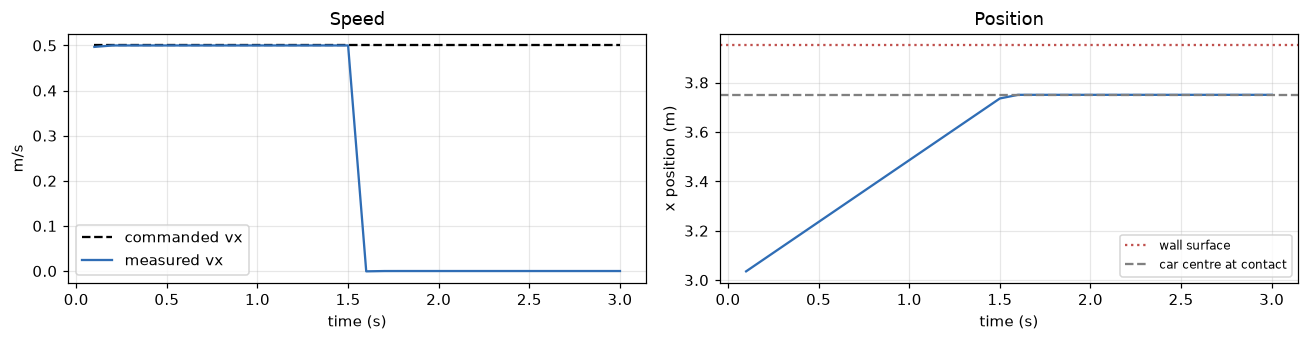

In [10]:
wall_log = run_commands([((0.5, 0, 0), 3.0)], start=(3.0, -1.0, 0.0))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].plot(wall_log["t"], wall_log["cmd"][:, 0], "k--", label="commanded vx")
axes[0].plot(wall_log["t"], wall_log["vel"][:, 0], color="#2f6db5", label="measured vx")
axes[0].set_xlabel("time (s)"); axes[0].set_ylabel("m/s"); axes[0].legend(); axes[0].set_title("Speed")
axes[1].plot(wall_log["t"], wall_log["pose"][:, 0], color="#2f6db5")
inner_wall = 4.0 - 0.05
axes[1].axhline(inner_wall, color="#c0504d", ls=":", label="wall surface")
axes[1].axhline(inner_wall - (car_cfg.wheelbase_half + car_cfg.wheel_radius), color="gray", ls="--", label="car centre at contact")
axes[1].set_xlabel("time (s)"); axes[1].set_ylabel("x position (m)"); axes[1].legend(fontsize=8); axes[1].set_title("Position")
plt.tight_layout(); plt.show()

## 7. Smoothing keyboard input

A keyboard key is either up or down: 0 or 1. If we sent that directly, the commanded speed would
jump from 0 to 0.8 m/s instantly. We **ramp** toward the requested speed instead, limited to
1.5 m/s² when speeding up and 3 m/s² when braking. This brings two benefits:

* **Realism**: real motors cannot change speed instantly.
* **Learnability**: the model will learn to *copy the recorded commands* from camera images. A
  jump from 0 to 0.8 happens between two camera frames that look almost identical, so the model
  cannot know *when* to jump. A smooth ramp is a much easier pattern to imitate.

**Important for later:** what we record as the "action" is the **ramped command** (orange), not the
raw key state (grey). That is what the model must learn to output.

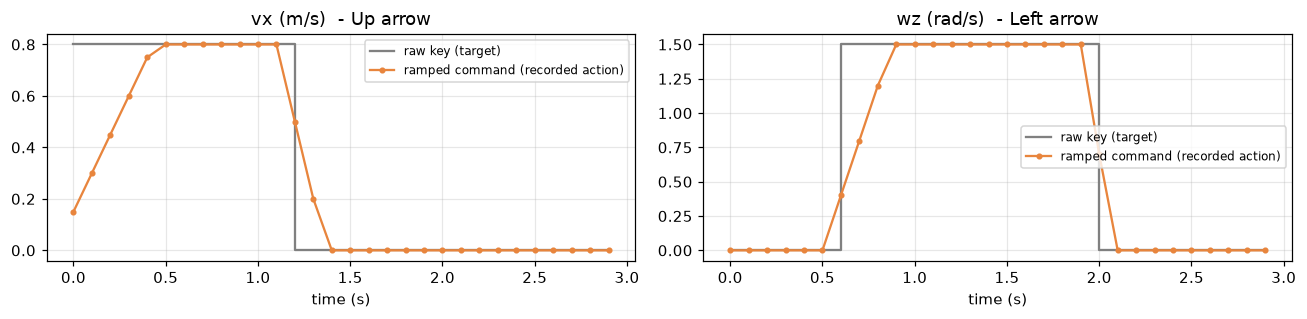

In [11]:
from carsim.teleop import KeyboardCommander
from genesis.vis.keybindings import Key

driver = KeyboardCommander(car_cfg, sim_cfg)
raw, ramped = [], []
for step in range(30):                      # 3 seconds at 10 Hz
    driver.held.clear()
    if step < 12: driver.held.add(Key.UP)   # hold "up" for 1.2 s
    if 6 <= step < 20: driver.held.add(Key.LEFT)  # hold "Left arrow" (rotate left) from 0.6 s to 2.0 s
    raw.append(driver.target()); ramped.append(driver.update())
raw, ramped = np.array(raw), np.array(ramped); tt = np.arange(30) / sim_cfg.control_hz
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, i, name in [(axes[0], 0, "vx (m/s)  - Up arrow"), (axes[1], 2, "wz (rad/s)  - Left arrow")]:
    ax.step(tt, raw[:, i], where="post", color="gray", label="raw key (target)")
    ax.plot(tt, ramped[:, i], "o-", color="#e8853d", ms=3, label="ramped command (recorded action)")
    ax.set_title(name); ax.set_xlabel("time (s)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. How fast is the simulation?

**Why it matters.** Imitation learning needs a few hours of your driving. Reinforcement learning
needs *millions* of steps of trial and error. Simulation speed decides whether RL takes hours or
weeks.

We measure two costs separately:
* **physics**: one control step = 10 physics steps;
* **rendering**: producing one FPV image.

This is one car in one scene. In notebook 05 we will run many cars in parallel (on the CPU, it turns out: see there)
(*vectorised environments*), which multiplies throughput.

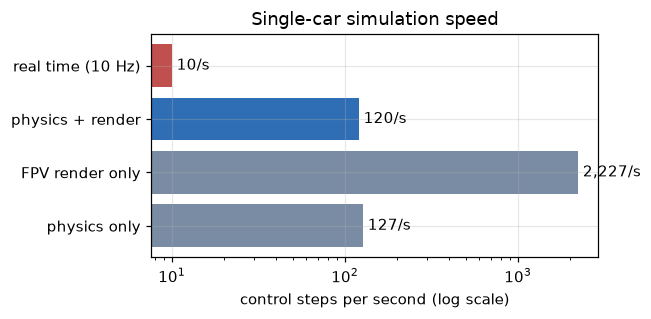

One car runs 12x faster than real time.
1 million RL steps with one car would take 2.3 hours -> we will want parallel cars.


In [12]:
car.reset(*START)
n = 200
t = time.perf_counter()
for i in range(n):
    car.step(0.3, 0.1 * np.sin(i / 10), 0.2)
physics_hz = n / (time.perf_counter() - t)
t = time.perf_counter()
for _ in range(n):
    car.render_fpv()
render_hz = n / (time.perf_counter() - t)
both_hz = 1 / (1 / physics_hz + 1 / render_hz)

fig, ax = plt.subplots(figsize=(6, 3))
names = ["physics only", "FPV render only", "physics + render", "real time (10 Hz)"]
vals = [physics_hz, render_hz, both_hz, sim_cfg.control_hz]
ax.barh(names, vals, color=["#7a8ca3", "#7a8ca3", "#2f6db5", "#c0504d"]); ax.set_xscale("log")
for i, v in enumerate(vals): ax.text(v, i, f" {v:,.0f}/s", va="center")
ax.set_xlabel("control steps per second (log scale)"); ax.set_title("Single-car simulation speed")
plt.tight_layout(); plt.show()
print(f"One car runs {both_hz / sim_cfg.control_hz:.0f}x faster than real time.")
print(f"1 million RL steps with one car would take {1e6 / both_hz / 3600:.1f} hours -> we will want parallel cars.")

## 9. Drive it yourself 🎮

The next cell opens two windows:
* **Genesis viewer**: a 3-D chase camera behind the car. **Click on it to give it keyboard focus.**
* **FPV**: what the car's camera sees, with the current command shown at the top.

| Key | Action |
|---|---|
| ↑ / ↓ | forward / backward |
| ← / → | rotate left / right |
| Q / E | **strafe** left / right (sideways, without turning) |
| Space | emergency stop |
| R | reset to the start position |
| Esc (or close the window) | quit and return to the notebook |

**Why a separate process?** The driving loop must run at a steady 10 Hz with its own window and
keyboard handling. Inside the Jupyter kernel, a crash or hang there would take down your notebook.
So the cell launches `scripts/drive_empty_arena.py` as a separate program and waits for it to finish. The
`--log` flag saves your commands and the car's poses so we can plot your drive afterwards.

**Try this:** drive to each coloured object; strafe around the red sphere while keeping it centred
in the FPV window (rotate and strafe together); drive into a wall. Notice how the driving
*feels*. Top speeds and acceleration live in `carsim/config.py` (`CarConfig`) if you want to experiment.

> **On a Mac:** the first time, macOS may ask to allow keyboard input or screen access for the terminal / Python;
> allow it, then re-run the cell.

In [ ]:
import subprocess
drive_log_path = RUNS / "first_drive.npz"
result = subprocess.run([sys.executable, str(PROJECT_ROOT / "scripts" / "drive_empty_arena.py"), "--log", str(drive_log_path)],
                        cwd=PROJECT_ROOT, capture_output=True, text=True)
print("\n".join(l for l in result.stdout.splitlines() if l.strip()))
if result.returncode != 0:
    print("Teleop exited with an error:\n", result.stderr[-2000:])

### 9.1 Look at your own drive

This is the same kind of plot as before, but for *your* driving. It previews notebook 03, where we
inspect recorded data before training on it. Things to notice:

* **Time-step regularity**: the steps should be evenly spaced at 0.1 s. Big gaps would mean the
  computer couldn't keep up, which would corrupt the dataset timing.
* **How you use the three axes**: do you mostly turn and drive, or strafe a lot? Your habits are
  exactly what the model will learn. Mixing styles from episode to episode makes learning harder
  (we discussed this when choosing the flow-matching head).

171 control steps over 17.0 s; step interval mean 99.9 ms, max 131 ms


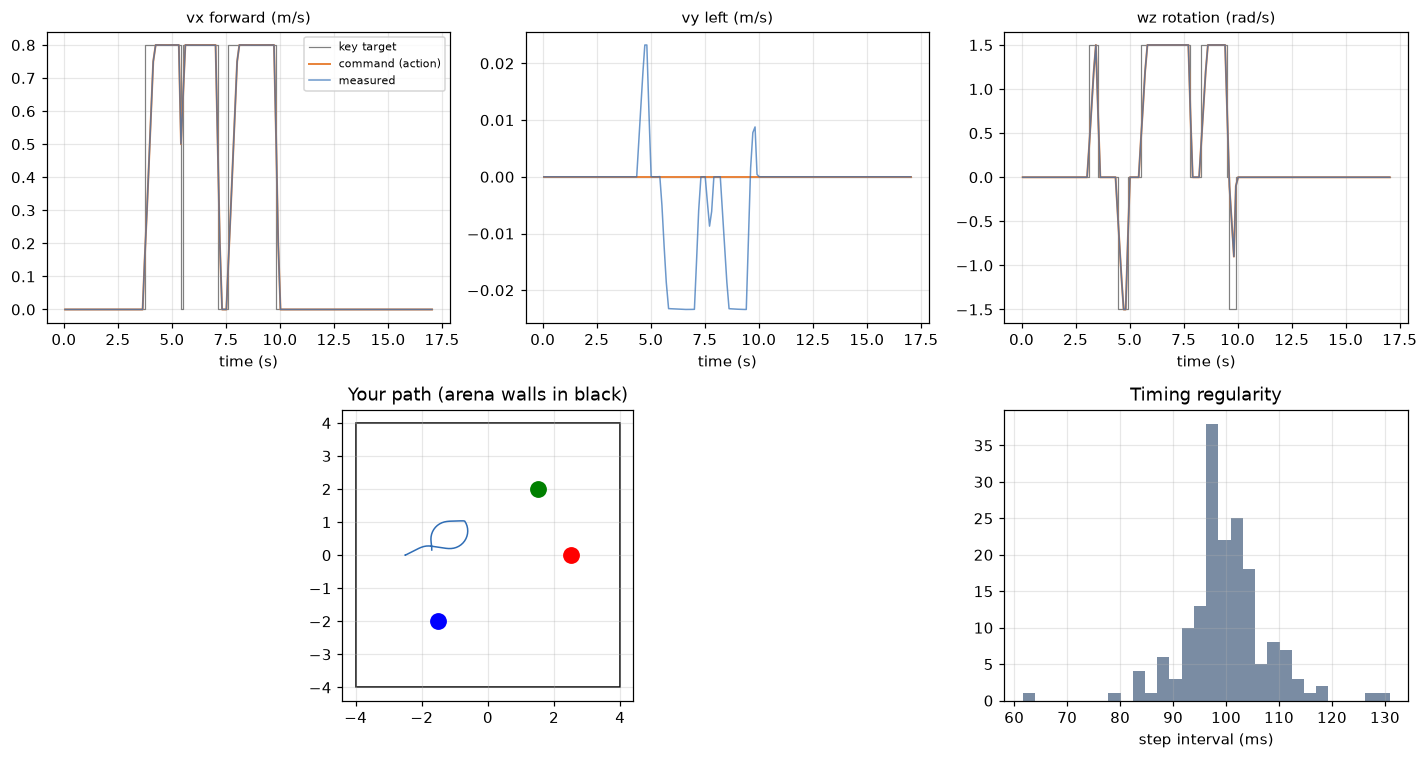

In [2]:
drive_log_path = RUNS / "first_drive.npz"   # written by the driving cell above
if not drive_log_path.exists():
    print("No drive log yet - run the teleop cell above first.")
else:
    d = np.load(drive_log_path)
    t = d["t"]; dt = np.diff(t)
    print(f"{len(t)} control steps over {t[-1]:.1f} s; step interval mean {dt.mean()*1000:.1f} ms, max {dt.max()*1000:.0f} ms")
    fig = plt.figure(figsize=(13, 7)); gsp = fig.add_gridspec(2, 3)
    labels = ["vx forward (m/s)", "vy left (m/s)", "wz rotation (rad/s)"]
    for i in range(3):
        ax = fig.add_subplot(gsp[0, i])
        ax.step(t, d["target"][:, i], where="post", color="gray", lw=0.8, label="key target")
        ax.plot(t, d["command"][:, i], color="#e8853d", lw=1.3, label="command (action)")
        ax.plot(t, d["velocity"][:, i], color="#2f6db5", lw=1, alpha=0.7, label="measured")
        ax.set_title(labels[i], fontsize=10); ax.set_xlabel("time (s)")
    fig.axes[0].legend(fontsize=7)
    ax = fig.add_subplot(gsp[1, 0:2]); p = d["pose"]
    ax.plot(p[:, 0], p[:, 1], color="#2f6db5", lw=1)
    ax.add_patch(plt.Rectangle((-4, -4), 8, 8, fill=False, color="k"))
    for xy, c in [((2.5, 0), "red"), ((1.5, 2), "green"), ((-1.5, -2), "blue")]:
        ax.plot(*xy, "o", color=c, ms=10)
    ax.set_aspect("equal"); ax.set_title("Your path (arena walls in black)")
    ax = fig.add_subplot(gsp[1, 2])
    ax.hist(dt * 1000, bins=30, color="#7a8ca3"); ax.set_xlabel("step interval (ms)"); ax.set_title("Timing regularity")
    plt.tight_layout(); plt.show()

## 10. Summary and next step

**What we verified:**
- ✅ PyTorch sees the device (`cuda`, `mps` or `cpu`), and we know how fast it is.
- ✅ Genesis works, and the car follows (vx, vy, wz) commands almost exactly, strafes sideways, and is stopped by walls.
- ✅ The FPV camera points forward and sees both nearby floor and distant objects.
- ✅ Keyboard commands are smoothed into learnable ramps, and the control loop runs at a steady 10 Hz.
- ✅ The simulation runs much faster than real time; for RL we will still want parallel cars.

**Things to think about before notebook 01:**
1. Did the driving feel right? (Speeds and acceleration are in `carsim/config.py`.)
2. Is the FPV view good? (Camera height, tilt, field of view.) Remember it is *all* the model sees.

**Next: notebook 01, the environment.** Obstacle shapes and sizes, how goal objects and colours are chosen,
random layouts per episode, and how "success" is defined.